# Previsão de churn: quando 80% de acerto quase não supera o chute

**Objetivo:** prever quais clientes de uma empresa de telecomunicações vão cancelar o serviço (*churn*).

Churn é a taxa de cancelamento de clientes em um período. Em negócios de assinatura, ele afeta diretamente receita e crescimento: saber quem tende a cancelar permite agir antes (desconto, contato do suporte, revisão de plano).

> **Sobre os dados:** este é um **dataset sintético**, gerado no próprio notebook (1.200 clientes, semente fixa = resultados reproduzíveis). O objetivo do case é praticar o fluxo de classificação e, principalmente, a avaliação correta do modelo. Os números não representam uma empresa real.

## 1. Gerando os dados

Cinco variáveis por cliente: idade, tempo de contrato, gasto mensal, chamados ao suporte e atraso de pagamento. A chance de cancelar foi construída para subir com gasto, chamados e atraso, e cair com o tempo de contrato.

In [1]:
#Gerando dataset para estudo de caso.

import numpy as np
import pandas as pd

np.random.seed(42)
n = 1200

df = pd.DataFrame({
    "idade": np.random.randint(18, 75, n),
    "tempo_contrato_meses": np.random.randint(1, 60, n),
    "gasto_mensal": np.random.uniform(50, 500, n),
    "suporte_chamados": np.random.poisson(2, n),
    "atraso_pagamento": np.random.binomial(1, 0.3, n)
})

logit = (
    -0.03 * df["tempo_contrato_meses"] +
    0.005 * df["gasto_mensal"] +
    0.8 * df["atraso_pagamento"] +
    0.4 * df["suporte_chamados"]
)

prob = 1 / (1 + np.exp(-logit))
df["churn"] = np.random.binomial(1, prob)

df.to_csv("churn.csv", index=False)

## 2. Primeira olhada e qualidade dos dados

Sem duplicados e sem nulos: dados limpos, todos numéricos.

In [2]:
df.head()

,idade,tempo_contrato_meses,gasto_mensal,suporte_chamados,atraso_pagamento,churn
0,56,20,149.252506,0,0,0
1,69,33,238.279905,5,0,1
2,46,20,141.610226,2,1,1
3,32,49,428.203583,1,1,1
4,60,12,128.387001,2,0,1


In [3]:
df.tail()

,idade,tempo_contrato_meses,gasto_mensal,suporte_chamados,atraso_pagamento,churn
1195,23,3,51.042897,0,0,1
1196,43,28,69.872871,3,0,1
1197,71,10,203.802082,0,0,1
1198,21,51,334.807849,3,1,1
1199,36,35,81.063293,2,0,1


In [4]:
df.shape

(1200, 6)

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

idade                   0
tempo_contrato_meses    0
gasto_mensal            0
suporte_chamados        0
atraso_pagamento        0
churn                   0
dtype: int64

In [7]:
df.describe()

,idade,tempo_contrato_meses,gasto_mensal,suporte_chamados,atraso_pagamento,churn
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,46.317500,30.280000,272.270751,1.986667,0.301667,0.764167
std,16.451157,16.860709,128.676932,1.428819,0.459173,0.424696
min,18.000000,1.000000,50.084780,0.000000,0.000000,0.000000
25%,33.000000,15.750000,157.552549,1.000000,0.000000,1.000000
50%,46.000000,30.000000,274.232697,2.000000,0.000000,1.000000
75%,61.000000,45.000000,383.105796,3.000000,1.000000,1.000000
max,74.000000,59.000000,499.871212,9.000000,1.000000,1.000000


## 3. A primeira descoberta: as classes estão desbalanceadas

**76% dos clientes cancelam.** Aqui a classe majoritária é justamente o churn (o contrário do que costuma acontecer). Isso vai pesar na avaliação: um modelo que diga "todo mundo cancela" já acerta a maioria.

In [8]:
df['churn'].value_counts(normalize=True) * 100

churn
1    76.416667
0    23.583333
Name: proportion, dtype: float64

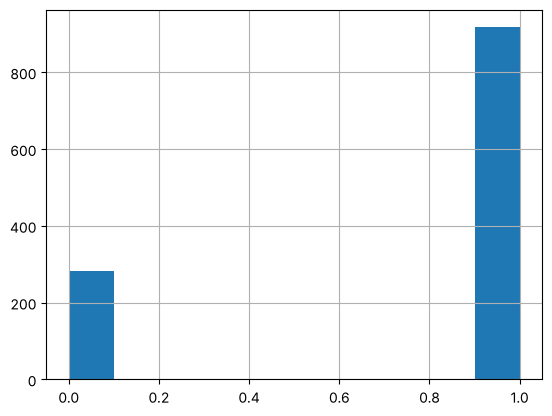

In [9]:
import matplotlib.pyplot as plt
df["churn"].hist()
plt.show()

## 4. Análise exploratória

Correlação entre as variáveis, distribuição de cada uma e outliers.

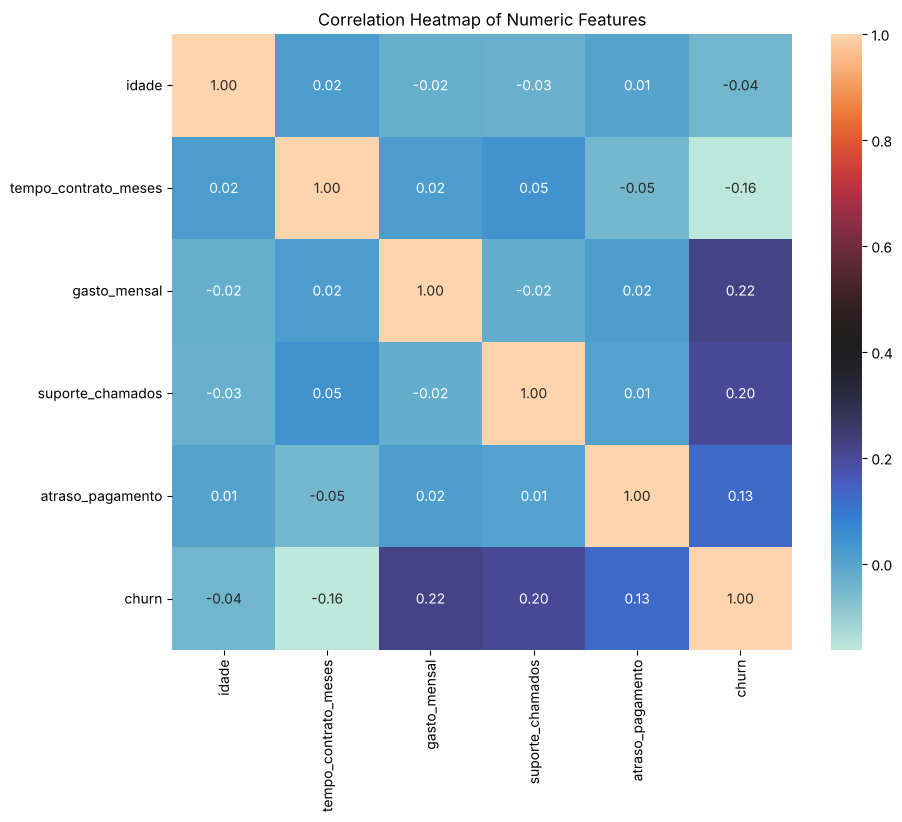

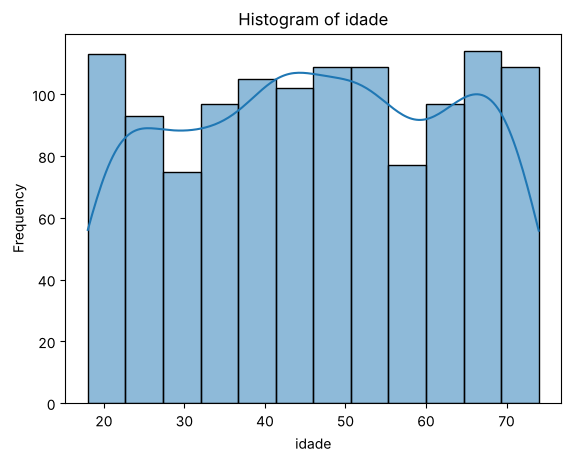

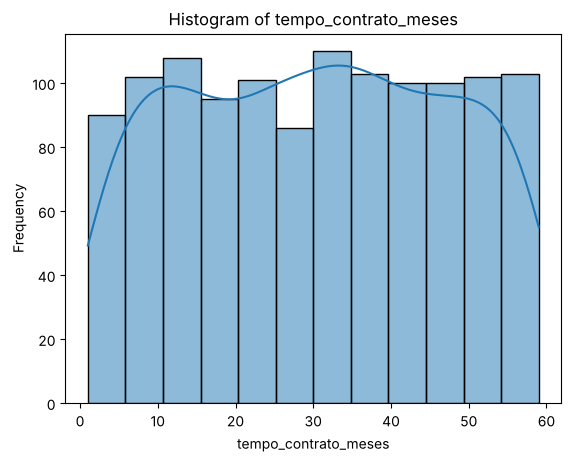

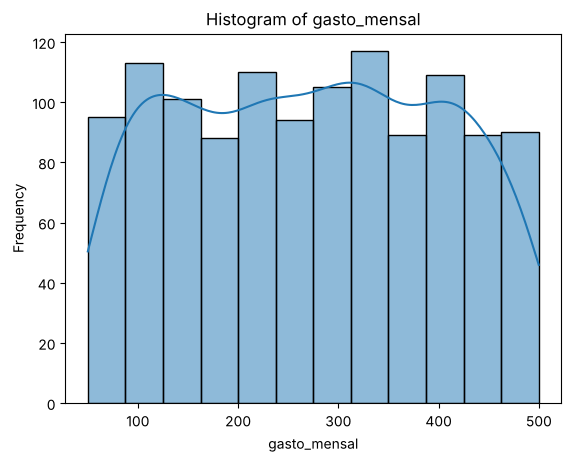

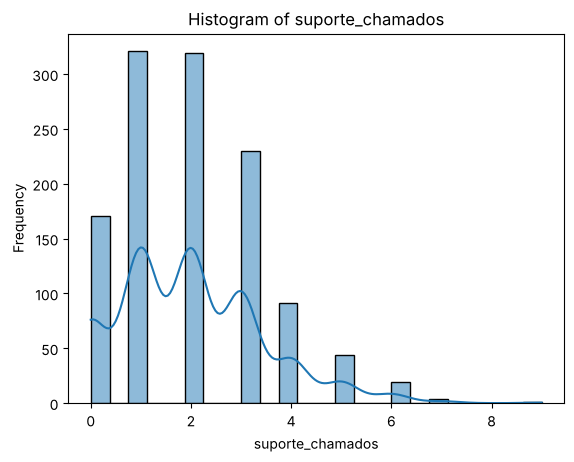

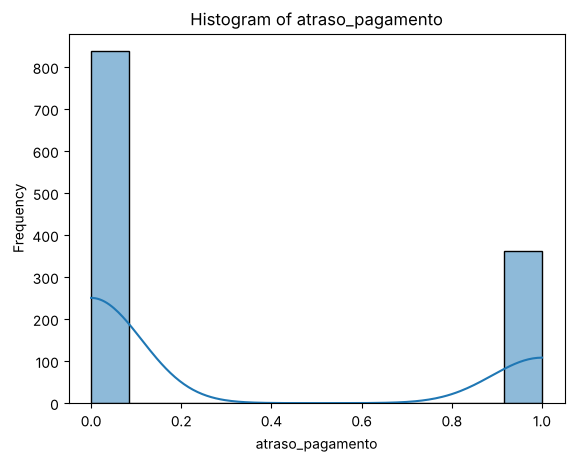

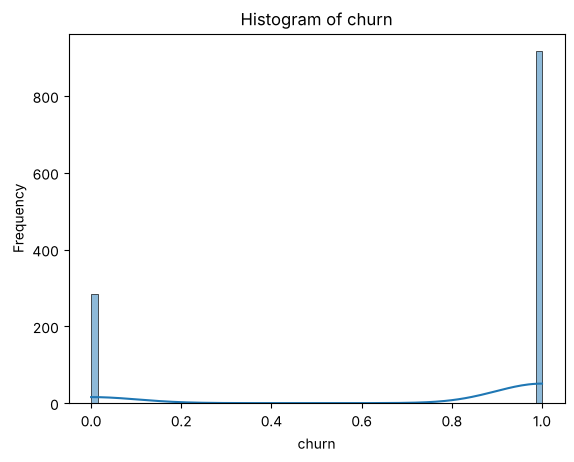

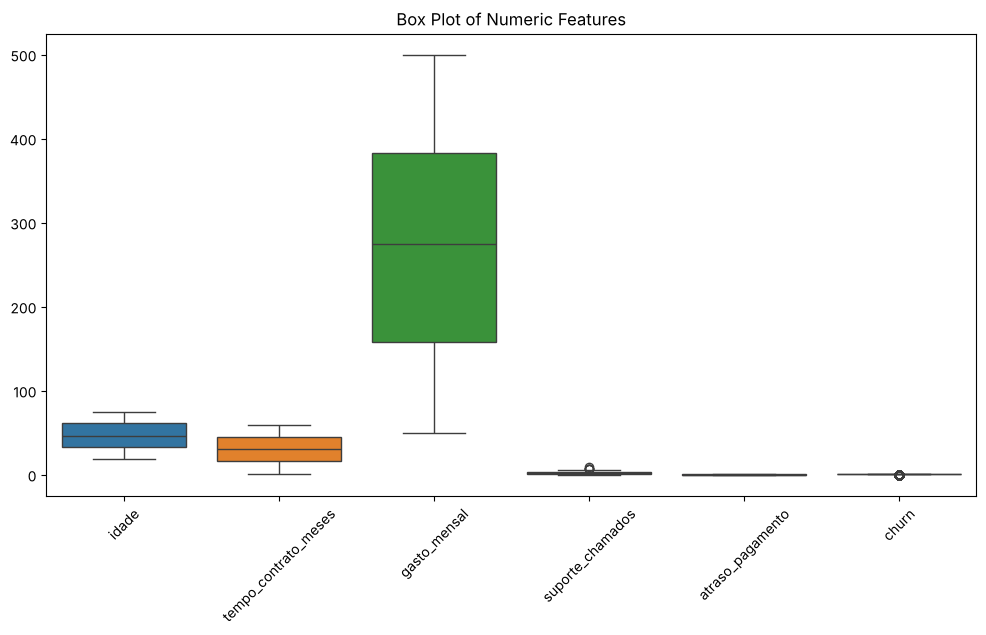

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# Separating only numeric data for numeric correlations
numeric_df = df.select_dtypes(include=[np.number])

# Correlation Heatmap (if there are four or more numeric columns)
if numeric_df.shape[1] >= 4:
    plt.figure(figsize=(10,8))
    sns.heatmap(numeric_df.corr(), annot=True, cmap='icefire', fmt='.2f')
    plt.title('Correlation Heatmap of Numeric Features')
    plt.show()
else:
    print('Not enough numeric columns for a correlation heatmap.')

# Histograms for distribution analysis
numeric_columns = numeric_df.columns
for col in numeric_columns:
    plt.figure()
    sns.histplot(df[col], kde=True)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

# Box Plot to detect outliers
plt.figure(figsize=(12, 6))
sns.boxplot(data=numeric_df)
plt.title('Box Plot of Numeric Features')
plt.xticks(rotation=45)
plt.show()

In [11]:
correlation_matrix = numeric_df.corr().abs()
sorted_correlations = correlation_matrix.unstack().sort_values(ascending=False)

# Filter out self-correlations and duplicate pairs
pairs = sorted_correlations[sorted_correlations != 1.0]
unique_pairs = pairs.reset_index()
unique_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
unique_pairs = unique_pairs[unique_pairs['Feature 1'] != unique_pairs['Feature 2']]
unique_pairs = unique_pairs.loc[~unique_pairs[['Feature 1', 'Feature 2']].apply(frozenset, axis=1).duplicated()]

print("Top 10 features with the highest absolute correlations:")
display(unique_pairs.head(10))

Top 10 features with the highest absolute correlations:


,Feature 1,Feature 2,Correlation
0,gasto_mensal,churn,0.221083
2,suporte_chamados,churn,0.203729
4,tempo_contrato_meses,churn,0.162569
6,churn,atraso_pagamento,0.125619
8,atraso_pagamento,tempo_contrato_meses,0.046362
10,tempo_contrato_meses,suporte_chamados,0.045023
12,churn,idade,0.044066
14,idade,suporte_chamados,0.027815
16,gasto_mensal,idade,0.024859
18,idade,tempo_contrato_meses,0.022029


Pela análise, é visível que o gasto mensal, o número de suporte chamado e o tempo de contrato(meses) são as 3 variavéis com maior correlação com a taxa de cancelamento (*churn*), em seguida a relação entre o *Churn* e atraso no pagamento também apontando uma correlação relevante ao estudo.

## 5. Modelagem

**A régua primeiro:** antes de qualquer modelo, o `DummyClassifier` chuta sempre a classe mais frequente ("cancela"). Qualquer modelo precisa superar isso.

In [12]:
X= df.drop('churn', axis=1)
y=df["churn"]

In [13]:
from sklearn.model_selection import train_test_split
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_treino, y_treino)
print(dummy.score(X_teste, y_teste))

0.7875


**78,75% de acerto sem olhar nenhuma variável.** Essa é a nota que o modelo precisa bater.

Primeiro modelo, uma Árvore de Decisão:

# Machine Learning
Nosso objetivo é prever uma categoria (churn sim ou não) com isso adotaremos o modelo para classificação Decision Tree.
Os dados estão limpos e não há nenhum texto nos dados, apenas números.

In [15]:
from sklearn.tree import DecisionTreeClassifier

modelo = DecisionTreeClassifier(random_state=42)
modelo.fit(X_treino, y_treino)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [16]:
previsoes = modelo.predict(X_teste)

In [17]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(accuracy_score(y_teste, previsoes))         # % de acertos
print(confusion_matrix(y_teste, previsoes))        # matriz de acertos e erros
print(classification_report(y_teste, previsoes))   # relatório completo (precisão, recall, f1)

0.7375
[[ 22  29]
 [ 34 155]]
              precision    recall  f1-score   support

           0       0.39      0.43      0.41        51
           1       0.84      0.82      0.83       189

    accuracy                           0.74       240
   macro avg       0.62      0.63      0.62       240
weighted avg       0.75      0.74      0.74       240



A Árvore acertou 73,75%: **pior que o chute**. Comparando mais algoritmos pela accuracy:

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

modelos = {
    "Árvore de Decisão": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Regressão Logística": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
}

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsao = modelo.predict(X_teste)
    print(nome, "->", accuracy_score(y_teste, previsao))

Árvore de Decisão -> 0.7375


Random Forest -> 0.7666666666666667
Regressão Logística -> 0.8
KNN -> 0.7708333333333334


## 6. O Paradoxo da Acurácia: comparando com as métricas certas

Accuracy sozinha engana quando as classes são desbalanceadas. A tabela abaixo compara todos os modelos com o baseline em **Recall** (de quem cancelou, quantos o modelo pegou), **Precision** (de quem ele apontou, quantos cancelaram de verdade) e **F1** (equilíbrio entre os dois).

Também incluí o **Recall de quem fica**: de todos os clientes que **não** cancelam, quantos o modelo reconhece. O baseline zera essa métrica, porque nunca prevê "fica".

Regressão Logística e KNN recebem os dados em escala (`StandardScaler`), porque usam coeficientes e distâncias; as árvores não precisam.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, precision_score, f1_score

scaler = StandardScaler()
X_treino_esc = scaler.fit_transform(X_treino)
X_teste_esc = scaler.transform(X_teste)

comparacao = {
    "Baseline (Dummy)":    (DummyClassifier(strategy="most_frequent"), X_treino, X_teste),
    "Árvore de Decisão":   (DecisionTreeClassifier(random_state=42), X_treino, X_teste),
    "Random Forest":       (RandomForestClassifier(random_state=42), X_treino, X_teste),
    "Regressão Logística": (LogisticRegression(max_iter=1000), X_treino_esc, X_teste_esc),
    "KNN":                 (KNeighborsClassifier(), X_treino_esc, X_teste_esc),
}

resultados = {}
for nome, (modelo, X_tr, X_te) in comparacao.items():
    modelo.fit(X_tr, y_treino)
    pred = modelo.predict(X_te)
    resultados[nome] = {
        "Accuracy": accuracy_score(y_teste, pred),
        "Recall (churn)": recall_score(y_teste, pred),
        "Precision (churn)": precision_score(y_teste, pred, zero_division=0),
        "F1 (churn)": f1_score(y_teste, pred),
        "Recall (quem fica)": recall_score(y_teste, pred, pos_label=0),
    }

pd.DataFrame(resultados).T.round(3)

,Accuracy,Recall (churn),Precision (churn),F1 (churn),Recall (quem fica)
Baseline (Dummy),0.788,1.000,0.788,0.881,0.000
Árvore de Decisão,0.738,0.820,0.842,0.831,0.431
Random Forest,0.767,0.915,0.812,0.861,0.216
Regressão Logística,0.800,0.958,0.819,0.883,0.216
KNN,0.771,0.894,0.828,0.860,0.314


## 7. O que o modelo considera importante

Importância das Features para o modelo: Árvore de Decisão


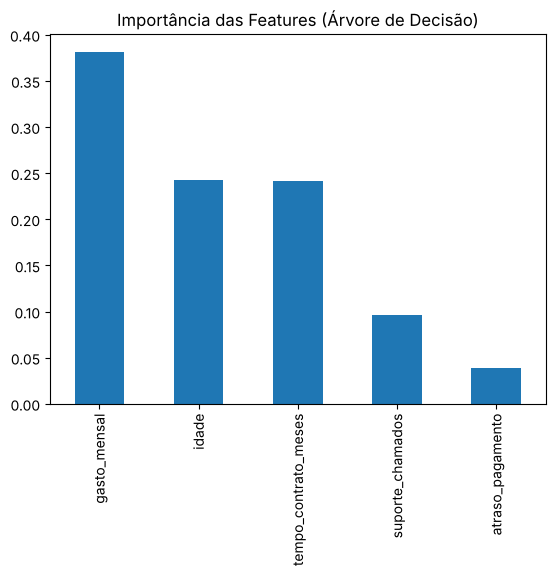

Importância das Features para o modelo: Random Forest


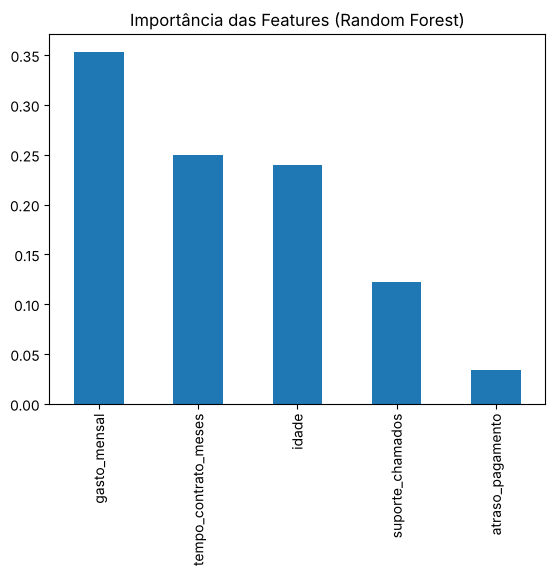

Coeficientes das Features para o modelo: Regressão Logística


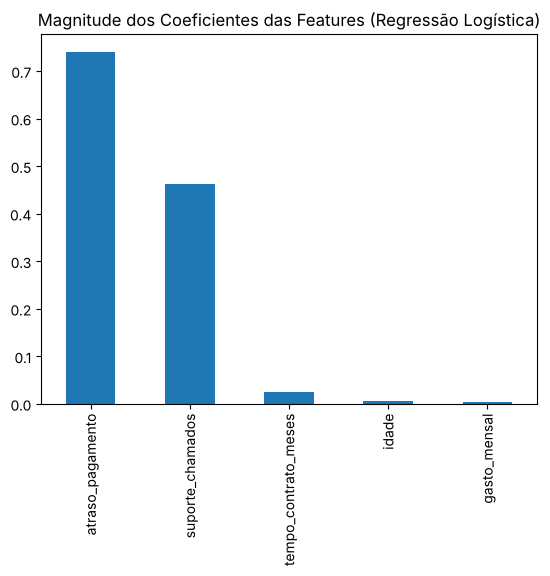

O modelo KNN não possui atributo feature_importances_ ou coef_.


In [20]:
for nome, modelo_treinado in modelos.items():
    if hasattr(modelo_treinado, 'feature_importances_'):
        print(f'Importância das Features para o modelo: {nome}')
        importancias = pd.Series(modelo_treinado.feature_importances_, index=X.columns)
        importancias.sort_values(ascending=False).plot(kind="bar")
        plt.title(f'Importância das Features ({nome})')
        plt.show()
    elif hasattr(modelo_treinado, 'coef_'):
        print(f'Coeficientes das Features para o modelo: {nome}')
        coeficientes = pd.Series(modelo_treinado.coef_[0], index=X.columns)
        coeficientes.abs().sort_values(ascending=False).plot(kind="bar")
        plt.title(f'Magnitude dos Coeficientes das Features ({nome})')
        plt.show()
    else:
        print(f'O modelo {nome} não possui atributo feature_importances_ ou coef_.')


## 8. Teste: dar mais peso à classe minoritária

`class_weight='balanced'` faz o modelo "prestar mais atenção" nos erros da classe menor (quem fica), sem alterar os dados.

In [21]:
log_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
log_bal.fit(X_treino_esc, y_treino)
pred_bal = log_bal.predict(X_teste_esc)

print(classification_report(y_teste, pred_bal))

              precision    recall  f1-score   support

           0       0.41      0.80      0.54        51
           1       0.93      0.69      0.79       189

    accuracy                           0.71       240
   macro avg       0.67      0.75      0.67       240
weighted avg       0.82      0.71      0.74       240



Com `class_weight='balanced'`, o modelo passa a reconhecer **80% dos clientes que ficam** (antes, 22%), e quando ele aponta churn **acerta 93%** das vezes. O custo: deixa de pegar parte dos que cancelam (recall do churn cai de 96% para 69%). Não existe modelo "certo" aqui: é um **trade-off de negócio**.

## Conclusão

Após a análise exploratória e a comparação entre quatro algoritmos (Árvore de Decisão, Random Forest, KNN e Regressão Logística), a Regressão Logística teve a maior acurácia: 80%.

Entretanto, o baseline que prevê sempre "cancela" já acerta 78,75%. O ganho real foi de apenas 1,25 ponto percentual, e no F1 do churn o melhor modelo empata com o chute (0,883 vs 0,881). A acurácia sozinha não mostra a qualidade da solução: esse é o **Paradoxo da Acurácia**.

As classes estão desbalanceadas (76% cancelam), o que leva os modelos a favorecer a classe majoritária e quase ignorar quem fica. Dar mais peso à classe minoritária (`class_weight`) muda esse equilíbrio.

**E daí, para o negócio:** a pergunta não é "qual modelo acerta mais", e sim "o que custa mais caro": deixar um cliente cancelar sem agir, ou gastar retenção com quem ia ficar de qualquer jeito? A resposta define qual versão do modelo usar.

**Próximos passos (v2):** validação cruzada, ajuste de limiar de decisão e aplicar o fluxo a um dataset real de churn.